# 2️⃣ 보완: DiD 최소 검출 효과 (MDE)

**질문**: 과거 프로모션 효과가 검출되지 않은 것은 효과가 없어서인가, 동 단위로는 원래 잡을 수 없어서인가?

**방법** (기존 `DiD_효과분석.ipynb`와 같은 DiD·플라시보 방식 사용)
1. 비교 후보 동을 하나씩 '가짜 시행 동'으로 놓는다.
2. 그 동의 시행 기간 지표에 효과를 인위로 더한다 (+0% ~ +100%).
3. 기존과 같은 DiD(시행 전 12개월 추이가 가장 비슷한 5개 동과 비교) + 플라시보 검정을 돌린다.
4. 플라시보 p ≤ 0.10이면 '검출'. 가짜 시행 동 전체 중 검출된 비율 = **검정력**.
5. 검정력이 80% 이상이 되는 최소 효과 = **최소 검출 효과(MDE)**.

| 사례 | 후보 동 | 시행 기간 |
|---|---|---|
| 1·2회차 시장 | 동지역 | 2024.04 ~ 07 (4개월) |
| 3회차 애월 | 읍면 | 2024.08 ~ 09 (2개월) |

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

have = {f.name for f in font_manager.fontManager.ttflist}
for name in ['NanumGothic', 'AppleGothic', 'Malgun Gothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in have:
        plt.rcParams['font.family'] = name; break
plt.rcParams['axes.unicode_minus'] = False

B = pd.read_csv('마스터_B_동월.csv', encoding='utf-8-sig')
A = pd.read_csv('마스터_A_동.csv', encoding='utf-8-sig')
B['ym'] = pd.PeriodIndex(B['기준연월'].astype(str), freq='M')
ZONE = dict(zip(A['행정동명'], A['권역']))
PANEL = {
    '방문': B.pivot(index='ym', columns='행정동명', values='방문').pipe(np.log),
    '카드': B.pivot(index='ym', columns='행정동명', values='금액_음식소매').clip(lower=1).pipe(np.log),
}
EXCL = {'일도1동', '중앙동', '애월읍', '추자면', '우도면'}
POOL_DONG = [d for d in ZONE if '동지역' in ZONE[d] and d not in EXCL]
POOL_EUP  = [d for d in ZONE if '동지역' not in ZONE[d] and d not in EXCL]
CASES = {'시장 (동지역, 4개월)': (POOL_DONG, '2024-04', '2024-07'),
         '애월 (읍면, 2개월)':   (POOL_EUP,  '2024-08', '2024-09')}
PRE_N, K, ALPHA = 12, 5, 0.10
EFFECTS = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 80, 100]     # %
print({k: len(v[0]) for k, v in CASES.items()}, '개 후보 동')

## DiD 함수 (기존 노트북과 동일)

In [ ]:
def did(P, treat, pool, start, end, k=K, pre_n=PRE_N):
    s, e = pd.Period(start, 'M'), pd.Period(end, 'M')
    pre = P.loc[s - pre_n: s - 1]
    tr = P[treat].mean(axis=1)
    cor = pre[pool].apply(lambda c: np.corrcoef(c, tr.loc[pre.index])[0, 1])
    ctrl = cor.nlargest(k).index.tolist()
    gap = tr - P[ctrl].mean(axis=1)
    return gap.loc[s:e].mean() - gap.loc[s - pre_n: s - 1].mean()

## 검정력 시뮬레이션

In [ ]:
rows = []
for var, P in PANEL.items():
    for case, (pool, s, e) in CASES.items():
        sp, ep = pd.Period(s, 'M'), pd.Period(e, 'M')
        # 효과를 심지 않은 각 동의 '가짜 효과' = 플라시보 분포
        base = {d: did(P, [d], [x for x in pool if x != d], s, e) for d in pool}
        for eff in EFFECTS:
            hit = []
            for d in pool:
                Pi = P.copy()
                Pi.loc[sp:ep, d] += np.log1p(eff / 100)                    # 효과 심기
                est = did(Pi, [d], [x for x in pool if x != d], s, e)
                plac = np.array([v for u, v in base.items() if u != d])    # 다른 동들의 플라시보
                hit.append((np.abs(plac) >= abs(est)).mean() <= ALPHA)
            rows.append({'지표': var, '사례': case, '심은 효과(%)': eff, '검정력': np.mean(hit)})
POW = pd.DataFrame(rows)

def mde(g, target=0.8):
    ok = g[g['검정력'] >= target]
    return f"{ok['심은 효과(%)'].min()}%" if len(ok) else f">{EFFECTS[-1]}%"
MDE = POW.groupby(['지표', '사례']).apply(mde, include_groups=False).rename('최소 검출 효과(검정력 80%)').reset_index()
display(MDE)
display(POW.pivot_table(index='심은 효과(%)', columns=['지표', '사례'], values='검정력').round(2))
POW.to_csv('DiD_검정력.csv', index=False, encoding='utf-8-sig'); MDE.to_csv('DiD_최소검출효과.csv', index=False, encoding='utf-8-sig')

## 실제 추정치와 비교: 동 단위 자연 변동 크기

In [ ]:
rows = []
for var, P in PANEL.items():
    for case, (pool, s, e) in CASES.items():
        base = np.array([did(P, [d], [x for x in pool if x != d], s, e) for d in pool])
        rows.append({'지표': var, '사례': case, '플라시보 효과 표준편차(%)': np.expm1(base.std()) * 100,
                     '플라시보 |효과| 90분위(%)': np.expm1(np.quantile(np.abs(base), 0.9)) * 100})
NOISE = pd.DataFrame(rows).round(1)
display(NOISE)

### 그림: 효과 크기별 검출 확률

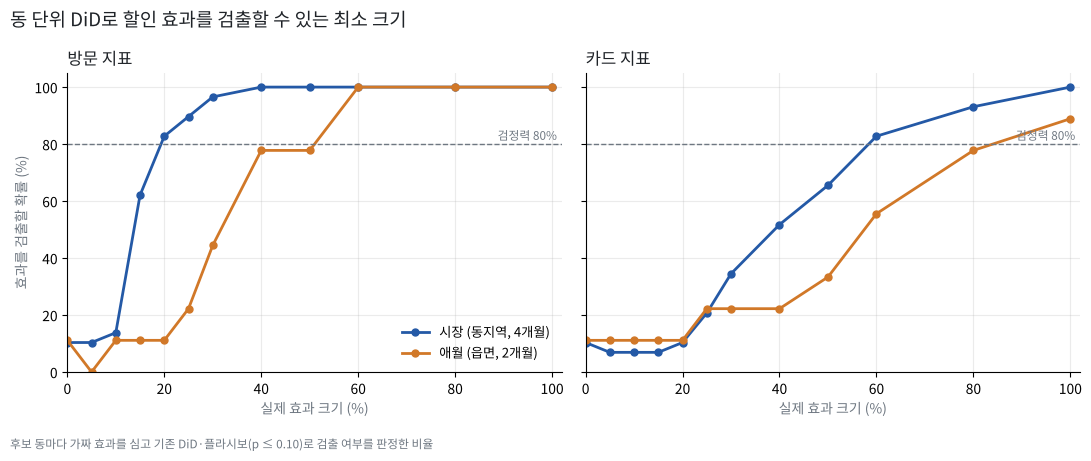

In [ ]:
INK, MUTED = '#1f2328', '#6e7781'
COL = {'시장 (동지역, 4개월)': '#2459A6', '애월 (읍면, 2개월)': '#D17828'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, var in zip(axes, PANEL):
    for case in CASES:
        g = POW[(POW['지표'] == var) & (POW['사례'] == case)]
        ax.plot(g['심은 효과(%)'], g['검정력'] * 100, marker='o', ms=5, lw=2, color=COL[case], label=case)
    ax.axhline(80, color=MUTED, ls='--', lw=1); ax.text(101, 81, '검정력 80%', fontsize=8.5, color=MUTED, ha='right', va='bottom')
    ax.set_title(f'{var} 지표', loc='left', fontsize=12, color=INK)
    ax.set_xlabel('실제 효과 크기 (%)', color=MUTED); ax.set_ylim(0, 105); ax.set_xlim(0, 102)
    ax.grid(alpha=0.25); ax.set_axisbelow(True)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
axes[0].set_ylabel('효과를 검출할 확률 (%)', color=MUTED)
axes[0].legend(frameon=False, fontsize=9.5, loc='lower right')
fig.suptitle('동 단위 DiD로 할인 효과를 검출할 수 있는 최소 크기', x=0.01, ha='left', fontsize=13.5, color=INK)
fig.text(0.01, -0.04, '후보 동마다 가짜 효과를 심고 기존 DiD·플라시보(p ≤ 0.10)로 검출 여부를 판정한 비율', fontsize=8.5, color=MUTED)
plt.tight_layout(); plt.savefig('DiD_최소검출효과.png', dpi=200, bbox_inches='tight'); plt.show()

## 결론
| 사례 | 방문 MDE | 카드 MDE | 자연 변동 (플라시보 표준편차, 방문) |
|---|---|---|---|
| 시장 (동지역, 4개월) | **20%** | 60% | 6.9% |
| 애월 (읍면, 2개월) | **60%** | 100% | 13.2% |

- 동 단위 DiD로 효과를 80% 확률로 잡으려면, **동 전체 외국인 방문이 시장 사례는 20% 이상, 애월 사례는 60% 이상** 늘어야 한다. 카드 소비는 변동이 커서 60~100%가 필요하다.
- 과거 프로모션은 시장 2곳, 카페 36곳처럼 **동 안의 일부 상권**만 대상으로 했다. 상권에서 효과가 있었더라도 동 전체로 희석되면 이 기준에 미치지 못한다.
- → 2️⃣의 "효과 미검출"은 효과가 없었다는 증거가 아니라 **측정 단위의 한계**이며, 그래서 3️⃣ 효과값은 문헌값으로 대체했다.
- → 제언: 다음 회차는 **상권(존) 단위 + 가맹점 결제 데이터**로 효과를 측정하도록 설계해야 한다.

※ 읍면 후보가 9개뿐이라 애월 사례의 검정력은 약 11%p 단위로 거칠게 계산된다. 효과 0%일 때 검출률이 약 10%로 유의수준과 같아, 검정 방식 자체는 정상 작동한다.